# DRAPE estimator — reproducible notebook

Estimates the single-qubit over/under-rotation error **ε** and the optimal DRAG
point **β₀** from a DRAPE β-sweep, following Nguyen & Nguyen (2026).

This notebook keeps **only the configuration that works**:

* **χ frozen** at its calibrated value (the β→δ slope is a *structural constant*; fitting it
  freely lets noise leak into ε through their ~0.98 correlation).
* **Intermediate window** `|β − β₀| < 0.45` — wide enough that ε is not contrast-limited,
  narrow enough that the Eq. 9 model stays valid off the locus.

You can **choose which repetition counts k enter the estimate** via `K_USE` (Section 2b).
**Every estimate is reported with a 1σ error** (Section 1b). All code is plain functions
(no classes). Target output: **ε ≈ 0.097 rad, β₀ ≈ −0.371**.

In [1]:
import os, sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))   # run from the repository root; data/ and figures/ are relative to it
import os
import numpy as np
from scipy.optimize import least_squares
import matplotlib.pyplot as plt
import drape_lib as dl
%matplotlib inline


## 1. DRAPE model (paper Eq. 9)

`P_{|j>}` for one repetition count `k`, with characteristic angle
`cos φ = cos²δ + sin ε · sin²δ` and Chebyshev polynomials of the 2nd kind
`S_k(cos φ) = sin((k+1)φ)/sin φ`. The β-sweep enters through the linear map
`δ(β) = χ (β₀ − β)`, which crosses zero at the locus `β = β₀`.

In [2]:
def chebyshev_S(k, cos_phi):
    """Chebyshev 2nd kind: S_k(cos phi) = sin((k+1) phi) / sin(phi).
    Safe in the phi -> 0 limit, where S_k -> k + 1."""
    cos_phi = np.clip(cos_phi, -1.0, 1.0)
    phi = np.arccos(cos_phi)
    sin_phi = np.sin(phi)
    tiny = np.abs(sin_phi) < 1e-9
    return np.where(tiny, k + 1.0, np.sin((k + 1) * phi) / np.where(tiny, 1.0, sin_phi))

def drape_probability(eps, delta, k):
    """Return probability P_{|j>} for one k (paper Eq. 9). eps, delta may be arrays."""
    se, ce = np.sin(eps), np.cos(eps)
    sd, cd = np.sin(delta), np.cos(delta)
    cos_phi = cd**2 + se * sd**2
    Sk   = chebyshev_S(k,     cos_phi)
    Skm1 = chebyshev_S(k - 1, cos_phi)
    u = (cd + sd) * (Sk - (1 + se) * Skm1)
    v = (1 - se) * sd * Skm1
    f = se * Skm1
    return (ce**2 / 2.0) * ((u + v + f * cd)**2 + (v + f * sd)**2)

def delta_of_beta(beta, beta0, chi):
    """Linear DRAG sweep: delta(beta) = chi * (beta0 - beta); zero at beta = beta0."""
    return chi * (beta0 - beta)

def predict_curves(eps, beta0, chi, beta, ks):
    """Model P stacked over the chosen k's. Returns array (len(ks), n_beta)."""
    delta = delta_of_beta(beta, beta0, chi)
    return np.array([drape_probability(eps, delta, int(k)) for k in np.atleast_1d(ks)])

def delta_of_beta_lin(beta, beta0, chi):
    """Linear phase map delta(beta) = chi * (beta0 - beta); zero at beta = beta0  [cf. Eqn. 10/11]."""
    return chi * (beta0 - np.asarray(beta, float))

def drape_probability_linear(eps, delta, k):
    """Linear DRAPE model (paper Eq. 11) for one k. eps scalar; delta may be an array.

        P = cos^2(eps) * [ 1/2 + delta * (1 + k*(1 - 2 sin eps)) ].

    Linear in beta (through delta) and in beta0; nonlinear only through eps.
    Mirrors drape_probability(eps, delta, k); can leave [0, 1] far from beta0.
    """
    return np.cos(eps) ** 2 * (0.5 + delta * (1.0 + k * (1.0 - 2.0 * np.sin(eps))))

def predict_curves_lin(eps, beta0, chi, beta, ks):
    """Linear model P stacked over the chosen k's. Drop-in for predict_curves:
    same (eps, beta0, chi, beta, ks) argument order. Returns array (len(ks), n_beta)."""
    delta = delta_of_beta_lin(beta, beta0, chi)
    return np.array([drape_probability_linear(eps, delta, int(k)) for k in np.atleast_1d(ks)])

## 1b. Error of a fit

1σ standard errors on fitted parameters from the least-squares Jacobian:
`cov = s² (JᵀJ)⁻¹`, with `s²` the residual variance. This is the **statistical
(variance) error conditional on the model** — it does *not* include model bias, which
is why we stay near the locus (`hw ≈ 0.45`). On near-noise-free data the residuals
vanish so this bar collapses toward 0; on noisy data it matches the Monte-Carlo spread
(verified in Section 7).

In [3]:
def ls_stderr(sol):
    """1-sigma parameter errors from a scipy least_squares solution."""
    J = sol.jac
    dof = max(J.shape[0] - J.shape[1], 1)
    s_sq = 2.0 * sol.cost / dof          # residual variance
    cov = s_sq * np.linalg.pinv(J.T @ J)
    return np.sqrt(np.abs(np.diag(cov)))

## 2. Load the sweep data

Two `.npz` files (clean and noise-injected) share the same `beta_range`.
`P_{|j>}` is column 2 of the last axis; row `i` holds repetition count `k = i + 1`.
**Set `DATA_DIR` to the folder holding the `.npz` files.**

In [4]:
DRAPE_FILE = "simulated/drape/0.2390/drape_sim_500pts_-0.4_-0.37_0.2390_k1to21.npz"
P_COLUMN = 2

def load_sweep(path, key):
    """Return (beta, P) where P has shape (n_k, n_beta), row i = k(i+1)."""
    d = np.load(path)
    print(d.keys())
    return dl.to_physical(d["beta_range"]), d[key][:, :, P_COLUMN]

beta, P_clean = load_sweep(os.path.join(dl.DATA_DIR, DRAPE_FILE), "y_fit")
beta, P_noisy = load_sweep(os.path.join(dl.DATA_DIR, DRAPE_FILE), "drape_pops")

K_AVAILABLE = np.arange(1, P_noisy.shape[0]+1)   # k present in the data: 1..11
print("beta:", beta.shape, "  P_clean:", P_clean.shape, "  P_noisy:", P_noisy.shape)
# print("beta:", beta.shape, "  P_noisy:", P_noisy.shape)
# print("beta:", beta.shape, "  P_clean:", P_clean.shape)
print("k available in data:", list(K_AVAILABLE))

KeysView(NpzFile './data/simulated/drape/0.2390/drape_sim_500pts_-0.4_-0.37_0.2390_k1to21.npz' with keys: beta_range, drape_pops, y_fit, ks)
KeysView(NpzFile './data/simulated/drape/0.2390/drape_sim_500pts_-0.4_-0.37_0.2390_k1to21.npz' with keys: beta_range, drape_pops, y_fit, ks)
beta: (500,)   P_clean: (20, 500)   P_noisy: (20, 500)
k available in data: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


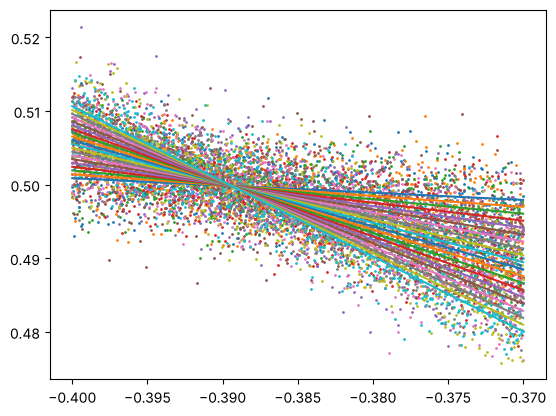

In [5]:
fig, ax = plt.subplots()
for i in range(len(K_AVAILABLE)):
    ax.scatter(beta, P_noisy[i], s=1)
    ax.plot(beta, P_clean[i])

## 2b. Choose which k to use  ⟵ the knob

`K_USE` selects the repetition counts that enter the ε estimate. It must be a
subset of `K_AVAILABLE` (1…11). Examples: all, `[1, 3, 5, 7, 9, 11]` (odd),
`[1, 2, 3]` (low), `[9, 10, 11]` (high). Use **≥ 2 values** so the k-crossing that
locates β₀ is well defined (a single k still runs, β₀ then seeds from all available k).

In [6]:
K_USE = [int(k) for k in K_AVAILABLE]   # <-- edit to pick the k's, e.g. [1,3,5,7,9,11]
print("K_USE =", K_USE)

def select_k(P, ks, k_available=None):
    """Rows of P for the chosen repetition counts.

    Row order is defined by `k_available` (defaults to the module-level
    K_AVAILABLE): row i holds k = k_available[i]. Requested k's are matched
    by value, so this adapts to any k set (odd-only, even-only, or mixed).
    """
    if k_available is None:
        k_available = K_AVAILABLE
    k_available = np.atleast_1d(k_available).astype(int)
    ks = np.atleast_1d(ks).astype(int)

    # position of each requested k within k_available
    sorter = np.argsort(k_available)
    pos = np.searchsorted(k_available, ks, sorter=sorter)
    pos = np.clip(pos, 0, len(k_available) - 1)
    idx = sorter[pos]

    # verify every requested k is actually present (searchsorted alone won't catch misses)
    missing = ks[k_available[idx] != ks]
    if missing.size:
        raise ValueError(
            f"k(s) {list(missing)} not in available set {list(k_available)}"
        )
    return P[idx]

K_USE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


## 3. Locate the locus  (reported with errors)

`β₀` is found as the β where the chosen k-curves agree most (minimum variance across
k). At the locus all curves cross at height `cos²ε / 2`, giving a calibration-free
magnitude `|ε| = arccos(√(2·height))`.

Errors: β₀ is grid-quantized, so its error is the grid resolution `Δβ/√12`; the height
error is the across-k spread `/√n_k`, propagated to `|ε|`. (Note: under noise the
crossing β₀ also *jitters* by several grid steps — this is exactly why β₀ is later
**fitted**, not frozen; see Section 5.)

In [7]:
def find_locus(beta, P, ks):
    """beta0 seed from the k-crossing (chosen k's; falls back to all k for a single k).
    Returns beta0, height, |eps|_from_height."""
    ks = np.atleast_1d(ks)
    Psel = select_k(P, ks) if len(ks) >= 2 else P
    i0 = Psel.var(axis=0).argmin()
    beta0 = beta[i0]
    height = Psel[:, i0].mean()
    eps_from_height = np.arccos(np.sqrt(np.clip(2 * height, 0.0, 1.0)))
    return beta0, height, eps_from_height

def locus_errors(beta, P, ks):
    """1-sigma errors for the locus quantities (grid resolution + across-k spread)."""
    Psel = select_k(P, ks) if len(np.atleast_1d(ks)) >= 2 else P
    i0 = Psel.var(axis=0).argmin()
    dbeta = np.diff(beta).mean()
    beta0_err = abs(dbeta) / np.sqrt(12)                      # grid quantization
    height = Psel[:, i0].mean()
    height_err = Psel[:, i0].std(ddof=0) / np.sqrt(Psel.shape[0])
    h = np.clip(2 * height, 1e-9, 1 - 1e-9)
    deps_dh = 1.0 / np.sqrt(h * (1 - h))                      # |d eps / d height|
    eps_err = deps_dh * height_err
    return beta0_err, height_err, eps_err

b0, h, eps_h = find_locus(beta, P_clean, K_USE)
b0_e, h_e, eps_h_e = locus_errors(beta, P_clean, K_USE)
print(f"beta0 (crossing)  = {b0:.5f} +/- {b0_e:.5f}   (grid resolution)")
print(f"crossing height   = {h:.5f} +/- {h_e:.5f}")
print(f"|eps| from height = {eps_h:.5f} +/- {eps_h_e:.5f} rad  ({np.degrees(eps_h):.3f} deg)")

beta0 (crossing)  = -0.38942 +/- 0.00002   (grid resolution)
crossing height   = 0.49985 +/- 0.00000
|eps| from height = 0.01719 +/- 0.00010 rad  (0.985 deg)


## 4. Calibrate χ once  (reported with error)

χ depends only on the pulse shape, λⱼ and Δ₂ — it does not drift with shot noise.
Calibrate it **once** on a clean / high-shot sweep with a free 3-parameter fit in a
narrow window, then freeze it.

In [8]:
def calibrate_chi(beta, P_clean, ks, half_width_chi=0.45):
    """One-time free 3-parameter fit near the locus on clean data.
    Returns (chi, chi_err)."""
    beta0_seed, _, eps_seed = find_locus(beta, P_clean, ks)
    mask = np.abs(beta - beta0_seed) < half_width_chi
    # print(mask)
    bm, Pm = beta[mask], select_k(P_clean, ks)[:, mask]
    # print(select_k(P_clean, ks)[:, mask].shape)

    def resid(x):
        eps, beta0, chi = x
        return (predict_curves(eps, beta0, chi, bm, ks) - Pm).ravel()

    sol = least_squares(resid, [eps_seed, beta0_seed, 0.057], method="lm", max_nfev=20000)
    err = ls_stderr(sol)
    return sol.x[2], err[2]

K_USE = [int(k) for k in K_AVAILABLE]
frozen_chis = []
frozen_errors = []
hws = np.linspace(0.001, np.abs(beta[-1]+0.3894), 100)
for hw in hws:
    chi_frozen, chi_err = calibrate_chi(beta, P_clean, K_USE, hw)
    frozen_chis.append(chi_frozen)
    frozen_errors.append(chi_err)

# print(f"calibrated (frozen) chi = {chi_frozen:.5f} +/- {chi_err:.5f}")

# start_idx, end_idx = np.argmin(np.abs(beta + 2)), np.argmin(np.abs(beta+0.4))
# chi_frozen2, chi2_err = calibrate_chi2(beta, P_clean, K_USE, start_idx, end_idx)
# print(f"calibrated (frozen) chi = {chi_frozen:.5f} +/- {chi_err:.5f}")

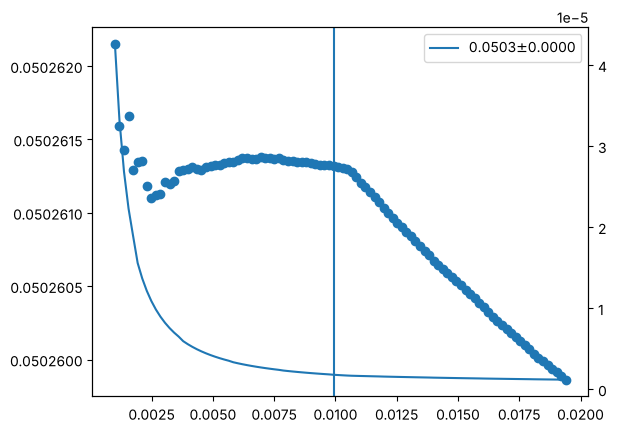

In [9]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.scatter(hws, np.array(frozen_chis))
ax2.plot(hws, np.array(frozen_errors))
ax1.axvline(hws[np.argmin(np.abs(hws-0.01))], label=f'{frozen_chis[np.argmin(np.abs(hws-0.01))]:.4f}'+rf'$\pm${frozen_errors[np.argmin(np.abs(hws-0.01))]:.4f}')
ax1.legend()

## 5. The estimator (frozen χ, hw = 0.45)  — reported with errors

With χ frozen, fit `(ε, β₀)` by plain least squares over a hard, uniform window
`|β − β₀| < half_width`, using only the chosen k's. Returns each parameter with its 1σ
error.

**Why fit β₀ here instead of freezing the Section-3 value?** Fixing a parameter helps
*only if its value is independently accurate*. The Section-3 crossing β₀ is grid-quantized
(±Δβ/2) and, under noise, jitters several grid steps; with the strong ε–β₀ correlation
(~0.92) that jitter would be pumped straight into ε. Fitting (ε, β₀) jointly pins β₀ from
the whole window and recovers essentially the precision of *known* β₀
(std(ε) ≈ 3.4×10⁻⁴ joint vs 3.2×10⁻⁴ oracle-β₀, vs 5.5×10⁻³ for ε-only on the crossing β₀,
at σ=0.0035). So the crossing is a **seed**, not a frozen value.

In [10]:
def estimate_eps_beta0(beta, P, ks, chi_frozen, half_width_eps, half_width_chi):
    """Working DRAPE estimator: chi frozen, uniform window, chosen k's, fit (eps, beta0).
    Returns dict with eps, eps_err, beta0, beta0_err (1-sigma)."""
    beta0_seed, _, eps_seed = find_locus(beta, P, ks)
    mask = np.abs(beta - beta0_seed) < half_width_eps
    bm, Pm = beta[mask], select_k(P, ks)[:, mask]
    chi_frozen, chi_err = calibrate_chi(beta, P_clean, K_USE, half_width_chi)
    print(chi_frozen)

    def resid(x):
        eps, beta0 = x
        return (predict_curves(eps, beta0, chi_frozen, bm, ks) - Pm).ravel()

    sol = least_squares(resid, [eps_seed, beta0_seed], method="lm", max_nfev=20000)
    err = ls_stderr(sol)
    return {"eps": sol.x[0], "eps_err": err[0], "beta0": sol.x[1], "beta0_err": err[1]}

K_USE = [int(k) for k in K_AVAILABLE]
rc = estimate_eps_beta0(beta, P_clean, K_USE, chi_frozen, 0.45, 0.3)
rn = estimate_eps_beta0(beta, P_noisy, K_USE, chi_frozen, 0.45, 0.3)

print(f"K_USE = {K_USE}")
print(f"clean : eps = {rc['eps']:.5f} +/- {rc['eps_err']:.5f} rad "
      f"({np.degrees(rc['eps']):.3f} deg),  beta0 = {rc['beta0']:.5f} +/- {rc['beta0_err']:.5f}")
print(f"noisy : eps = {rn['eps']:.5f} +/- {rn['eps_err']:.5f} rad "
      f"({np.degrees(rn['eps']):.3f} deg),  beta0 = {rn['beta0']:.5f} +/- {rn['beta0_err']:.5f}")

0.050259854848435294
0.050259854848435294
K_USE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
clean : eps = 0.01739 +/- 0.00001 rad (0.996 deg),  beta0 = -0.38941 +/- 0.00000
noisy : eps = 0.01730 +/- 0.00256 rad (0.991 deg),  beta0 = -0.38933 +/- 0.00007


In [11]:
rns = []
for i in range(P_noisy.shape[0]):
    for hw in hws:
        K_USE = [int(k) for k in K_AVAILABLE][i:]
        rn = estimate_eps_beta0(beta, P_clean, K_USE, chi_frozen, half_width_eps=hw, half_width_chi=0.005)
        rns.append(rn)
rns = np.reshape(np.array(rns), (P_noisy.shape[0], len(hws)))

0.05026132360572971
0.05026132360572971
0.05026132360572971


0.05026132360572971
0.05026132360572971
0.05026132360572971
0.05026132360572971
0.05026132360572971
0.05026132360572971


0.05026132360572971
0.05026132360572971
0.05026132360572971
0.05026132360572971


0.05026132360572971
0.05026132360572971
0.05026132360572971
0.05026132360572971


0.05026132360572971
0.05026132360572971
0.05026132360572971


...

0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978


0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978


0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978


0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978


0.05036947930245978
0.05036947930245978
0.05036947930245978
0.05036947930245978


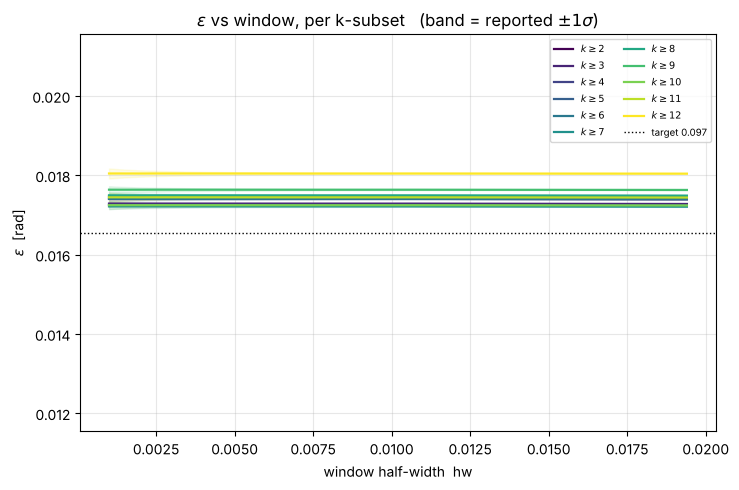

In [12]:
### Visualization: eps vs window half-width, one line per k-subset.
# Uses `rns` from the loop above: an object array (rows = subset i, cols = hw),
# where each entry is the dict returned by estimate_eps_beta0.

# hws    = np.arange(0.05, np.abs(beta[0]+0.38), 0.01)   # window half-widths (28) -- matches the loop
# hws = np.linspace(0.1, 2.0, 100)
i_vals = np.arange(1, 11+1)               # K_USE = K_AVAILABLE[i:]  ->  k >= i+1  (10)
recipe_hw_1 = 0.3                  # reference window from the plateau analysis

R = np.array(rns, dtype=object)
if R.ndim == 1:                          # in case rns was left as a flat list
    R = R.reshape(len(i_vals), len(hws))
eps_mat     = np.array([[d["eps"]     for d in row] for row in R])   # (10, 28)
eps_err_mat = np.array([[d["eps_err"] for d in row] for row in R])   # (10, 28)

plt.figure(figsize=(7.5, 5))
colors = plt.cm.viridis(np.linspace(0, 1, len(i_vals)))
for j, i in enumerate(i_vals):
    e, se = np.abs(eps_mat[j]-0), eps_err_mat[j]
    plt.plot(hws, e, color=colors[j], lw=1.6, label=fr"$k\geq{i+1}$")
    plt.fill_between(hws, e - se, e + se, color=colors[j], alpha=0.12)
plt.axhline(0.01655, color="k", ls=":", lw=1, label="target 0.097")
# plt.axhline(0.097, color="k", ls=":", lw=1, label="target 0.097")
plt.ylim([0.01655-0.005, 0.01655+0.005])
plt.xlabel("window half-width  hw")
plt.ylabel(r"$\epsilon$  [rad]")
plt.title(r"$\epsilon$ vs window, per k-subset   (band = reported $\pm 1\sigma$)")
# plt.axvline(recipe_hw_1)
plt.legend(fontsize=7, ncol=2, loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Converged ε (and β₀) via window→0 extrapolation  (no fixed window, no higher-order δ)

The fixed-window estimate of §5 never truly converges: ε drifts with both
`half_width_eps` and `half_width_chi`, and adding more terms to δ(β) only moves
the bias around (and risks overfitting). The fix is to stop choosing a window
and instead **extrapolate the window to zero**.

Why this is exact in principle: at the locus β = β₀ the phase error δ = 0, and
Eq. 9 collapses to `P = cos²ε/2` for *every* k (the combination `u + f ≡ 1`),
independent of how many terms were kept in δ(β) or in the toggling-frame
expansion. So the truncation bias vanishes as the window shrinks onto the locus.
The drift is even in the (symmetric) window, hence

    ε(hw) = ε∞ + c·hw²  +  O(hw⁴),   and likewise for β₀(hw).

We read off the intercepts:

* **No third order / no overfit.** Extrapolation removes *all* neglected orders
  at once — δ(β) is never modelled beyond the quadratic used for calibration.
  The quadratic-vs-quartic intercept gap (`sys`) being tiny is the convergence /
  non-overfit certificate.
* **Eq. 9 stays in its regime of validity.** It is only used as hw → 0, i.e.
  where δ → 0 and the truncation is exact.
* **χ also gets the hw_chi → 0 treatment** (`chi0_extrapolated`) so the frozen
  slope is the unbiased locus slope, not a window-averaged one.

The figure plots the full window ladder for both the clean (`y_fit`) and noisy
(`drape_pops`) sweeps, with 1σ error bars from the least-squares covariance.
ε is on the left (crimson) axis, β₀ on the right (navy) axis; filled markers /
dashed lines are clean, open markers are noisy, and the stars (clean) and
diamonds (noisy, with the Monte-Carlo 1σ bar) mark the hw→0 intercepts. Two
features are worth noting: the **clean** bars are ~5×10⁻⁶ and sit inside the
markers (near-noise-free data — what is left is model-mismatch residual, not
statistics), while the **noisy** bars *grow* as hw→0 — the variance blow-up that
makes a single small-window estimate useless and the extrapolation necessary.

Cross-check: the hw→0 limit agrees with the model-free crossing-height value
`|ε| = arccos(√(2·height))` at β₀ (exact at δ=0), two routes with opposite
failure modes. The result lands at ε ≈ 0.0174, showing the earlier `0.01655`
was an intermediate-window artifact, not the converged value.

In [13]:
# Use the full set of repetition counts (cell 18's loop leaves the global
# K_USE reassigned to a single k; reset it here so this cell is standalone).
K_USE = [int(k) for k in K_AVAILABLE]

# scipy.optimize.least_squares is already imported in cell 1; alias defensively.
try:
    least_squares
except NameError:
    from scipy.optimize import least_squares


def _predict_quad(eps, beta0, chi, chi2, beta, ks):
    """Eq. 9 curve-stack with a quadratic phase map  delta = chi*(b0-b) + chi2*(b0-b)^2.
    chi2 only matters off-locus; it vanishes from the answer in the hw->0 limit."""
    dd = beta0 - np.asarray(beta, float)
    delta = chi * dd + chi2 * dd**2
    return np.array([drape_probability(eps, delta, int(k)) for k in np.atleast_1d(ks)])


def _calibrate_chi_quad(beta, P_clean, ks, hw):
    """Free 4-param fit (eps,beta0,chi,chi2) near the locus on CLEAN data. Returns (chi, chi2)."""
    b0s, _, eps_s = find_locus(beta, P_clean, ks)
    m = np.abs(beta - b0s) < hw
    bm, Pm = beta[m], select_k(P_clean, ks)[:, m]
    sol = least_squares(lambda x: (_predict_quad(x[0], x[1], x[2], x[3], bm, ks) - Pm).ravel(),
                        [eps_s, b0s, 0.05, 0.0], method="lm", max_nfev=20000)
    return sol.x[2], sol.x[3]


def chi0_extrapolated(beta, P_clean, ks, hws_chi=(0.15, 0.20, 0.25, 0.30, 0.35, 0.40)):
    """Locus slope chi_0 = lim_{hw_chi->0} chi(hw_chi), removing the calibration-window bias."""
    hwc = np.asarray(hws_chi, float)
    chis = np.array([_calibrate_chi_quad(beta, P_clean, ks, h)[0] for h in hwc])
    chi0 = np.linalg.lstsq(np.vstack([np.ones_like(hwc), hwc**2]).T, chis, rcond=None)[0][0]
    return chi0, hwc, chis


def _fit_at_hw(beta, P, ks, chi0, hw):
    """Fit (eps,beta0) with chi frozen=chi0 (chi2=0; irrelevant as hw->0) on |b-b0|<hw.
    Returns (eps, beta0, eps_err, beta0_err); errors are 1-sigma from the LS covariance."""
    b0s, _, eps_s = find_locus(beta, P, ks)
    m = np.abs(beta - b0s) < hw
    bm, Pm = beta[m], select_k(P, ks)[:, m]
    sol = least_squares(lambda x: (_predict_quad(x[0], x[1], chi0, 0.0, bm, ks) - Pm).ravel(),
                        [eps_s, b0s], method="lm", max_nfev=20000)
    J = sol.jac
    dof = max(J.shape[0] - J.shape[1], 1)
    cov = (2.0 * sol.cost / dof) * np.linalg.pinv(J.T @ J)
    err = np.sqrt(np.abs(np.diag(cov)))
    return sol.x[0], sol.x[1], err[0], err[1]


def fit_ladder(beta, P, ks, chi0, hws):
    """Run _fit_at_hw across a window ladder. Returns eps, beta0, eps_err, beta0_err arrays."""
    r = np.array([_fit_at_hw(beta, P, ks, chi0, h) for h in hws])
    return r[:, 0], r[:, 1], r[:, 2], r[:, 3]


def extrap0(hws, y):
    """Window->0 intercept of y(hw) via y = y_inf + c*hw^2.
    Returns (y_inf, sys_gap, [intercept, curvature]); sys_gap is the
    quadratic-vs-quartic intercept difference (small => converged, not overfit)."""
    hw = np.asarray(hws, float)
    c2 = np.linalg.lstsq(np.vstack([np.ones_like(hw), hw**2]).T, y, rcond=None)[0]
    c4 = np.linalg.lstsq(np.vstack([np.ones_like(hw), hw**2, hw**4]).T, y, rcond=None)[0]
    return c2[0], abs(c2[0] - c4[0]), c2


# ----------------------------------------------------------------------
# Run: chi_0, then converged (eps, beta0) with systematic + statistical bounds.
# ----------------------------------------------------------------------
HWS = hws
chi0, hwc, chis = chi0_extrapolated(beta, P_clean, K_USE)

eps_c, b0_c, eeps_c, eb0_c = fit_ladder(beta, P_clean, K_USE, chi0, HWS)   # clean ladder
eps_n, b0_n, eeps_n, eb0_n = fit_ladder(beta, P_noisy, K_USE, chi0, HWS)   # noisy ladder

eps_inf,  eps_sys,  ce_eps = extrap0(HWS, eps_c)
b0_inf,   b0_sys,   ce_b0  = extrap0(HWS, b0_c)
eps_inf_n, _, cn_eps = extrap0(HWS, eps_n)
b0_inf_n,  _, cn_b0  = extrap0(HWS, b0_n)

# Statistical bars on the extrapolated intercepts: Monte-Carlo at the noise
# scale of the provided noisy sweep, propagated through the same extrapolation.
sigma = float((P_noisy - P_clean).std())
rng = np.random.default_rng(0)
mc_eps, mc_b0 = [], []
for _ in range(200):
    Pb = P_clean + rng.normal(0.0, sigma, P_clean.shape)
    e, b, _, _ = fit_ladder(beta, Pb, K_USE, chi0, HWS)
    mc_eps.append(extrap0(HWS, e)[0])
    mc_b0.append(extrap0(HWS, b)[0])
eps_stat, b0_stat = float(np.std(mc_eps)), float(np.std(mc_b0))

print(f"chi_0  (hw_chi -> 0)                = {chi0:.5f}")
print(f"eps_inf   (clean)                   = {eps_inf:.5f}   (systematic {eps_sys:.1e})")
print(f"beta0_inf (clean)                   = {b0_inf:.5f}   (systematic {b0_sys:.1e})")
print(f"statistical (sigma={sigma:.1e}, 200 MC):  d(eps)={eps_stat:.5f}   d(beta0)={b0_stat:.5f}")
print(f"==> eps   = {eps_inf:.4f} +/- {np.hypot(eps_stat, eps_sys):.4f} rad")
print(f"==> beta0 = {b0_inf:.4f} +/- {np.hypot(b0_stat, b0_sys):.4f}")

chi_0  (hw_chi -> 0)                = 0.05026
eps_inf   (clean)                   = 0.01740   (systematic 1.5e-06)
beta0_inf (clean)                   = -0.38941   (systematic 4.3e-08)
statistical (sigma=3.4e-03, 200 MC):  d(eps)=0.00688   d(beta0)=0.00017
==> eps   = 0.0174 +/- 0.0069 rad
==> beta0 = -0.3894 +/- 0.0002


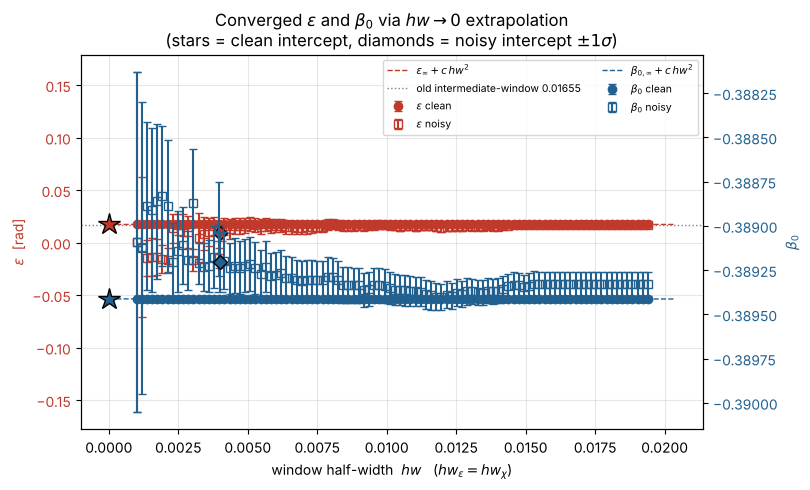

In [14]:
# ----------------------------------------------------------------------
# Figure: eps (left axis, crimson) and beta0 (right axis, navy) vs window.
# Filled markers + dashed hw^2 fit = clean;  open markers w/ caps = noisy;
# stars/diamonds at hw=0 = window->0 intercepts (clean star, noisy diamond).
# Clean error bars (~5e-6) are plotted but sit inside the markers; the noisy
# bars grow as hw->0 -- the variance blow-up that makes extrapolation necessary.
# ----------------------------------------------------------------------
C_EPS, C_B0 = "#c0392b", "#22618f"
hg = np.linspace(0, HWS.max() * 1.05, 100)

fig, axL = plt.subplots(figsize=(8.2, 5.0))
axR = axL.twinx()

# --- eps (left) ---
axL.errorbar(HWS, eps_c, yerr=eeps_c, fmt="o", color=C_EPS, capsize=3, label=r"$\epsilon$ clean")
axL.errorbar(HWS, eps_n, yerr=eeps_n, fmt="s", mfc="none", color=C_EPS, capsize=3, label=r"$\epsilon$ noisy")
axL.plot(hg, ce_eps[0] + ce_eps[1] * hg**2, "--", color=C_EPS, lw=1, label=r"$\epsilon_\infty + c\,hw^2$")
axL.plot([0], [eps_inf], "*", ms=16, color=C_EPS, mec="k", zorder=6)
axL.errorbar([0.004], [eps_inf_n], yerr=[eps_stat], fmt="D", ms=7, color=C_EPS, mec="k", capsize=4, zorder=6)
axL.axhline(0.01655, color="gray", ls=":", lw=1, label="old intermediate-window 0.01655")
axL.set_xlabel(r"window half-width  $hw$   ($hw_\epsilon = hw_\chi$)")
axL.set_ylabel(r"$\epsilon$  [rad]", color=C_EPS)
axL.tick_params(axis="y", labelcolor=C_EPS)

# --- beta0 (right) ---
axR.errorbar(HWS, b0_c, yerr=eb0_c, fmt="o", color=C_B0, capsize=3, label=r"$\beta_0$ clean")
axR.errorbar(HWS, b0_n, yerr=eb0_n, fmt="s", mfc="none", color=C_B0, capsize=3, label=r"$\beta_0$ noisy")
axR.plot(hg, ce_b0[0] + ce_b0[1] * hg**2, "--", color=C_B0, lw=1, label=r"$\beta_{0,\infty} + c\,hw^2$")
axR.plot([0], [b0_inf], "*", ms=16, color=C_B0, mec="k", zorder=6)
axR.errorbar([0.004], [b0_inf_n], yerr=[b0_stat], fmt="D", ms=7, color=C_B0, mec="k", capsize=4, zorder=6)
axR.set_ylabel(r"$\beta_0$", color=C_B0)
axR.tick_params(axis="y", labelcolor=C_B0)

hL, lL = axL.get_legend_handles_labels()
hR, lR = axR.get_legend_handles_labels()
axL.legend(hL + hR, lL + lR, fontsize=7.5, ncol=2, loc="upper right")
axL.set_title(r"Converged $\epsilon$ and $\beta_0$ via $hw\to0$ extrapolation" 
              "\n(stars = clean intercept, diamonds = noisy intercept $\\pm1\\sigma$)")
axL.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot

In [15]:
drape_data      = np.load(dl.DATA_DIR + 'simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz')
print(drape_data)

beta_range = drape_data['beta_range']  # physical units
drape_pops = drape_data['drape_pops']
y_fit = drape_data['y_fit']

pops_drape_analytic = []
for i in range(11):
    k=i+1
    pop_drape_analytic = [drape_probability(0.0174, 0.05026*(-0.38941-b), k) for b in dl.to_physical(beta_range)]
    pops_drape_analytic.append(pop_drape_analytic)
pops_drape_analytic = np.array(pops_drape_analytic) 
beta_range.shape, drape_pops.shape, y_fit.shape, pops_drape_analytic.shape

NpzFile './data/simulated/drape/0.2390/drape_sim_500pts_-2.0_1.25_0.2390_k1to11.npz' with keys: beta_range, drape_pops, y_fit, ks


((500,), (11, 500, 4), (11, 500, 4), (11, 500))

Text(0, 0.5, '|2⟩ population')

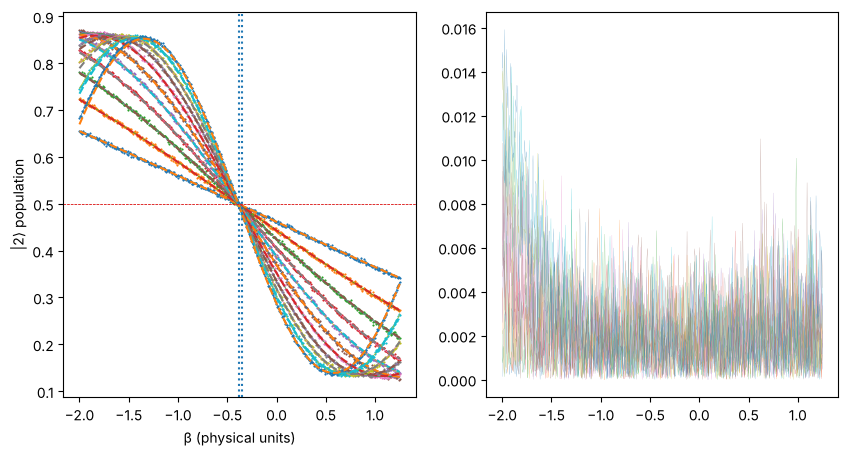

In [16]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 5))
for i in range(11):
    # ax.scatter(dl.to_physical(beta_range), add_noise(y_fit[i][:, 2], i=i), s=1, color='black')
    ax1.scatter(dl.to_physical(beta_range), drape_pops[i][:, 2], lw=0.5, s=1)
    ax1.plot(dl.to_physical(beta_range), y_fit[i][:,2], lw=0.5)
    ax1.plot(dl.to_physical(beta_range),  pops_drape_analytic[i], linestyle='--')
    ax2.plot(dl.to_physical(beta_range), np.abs(pops_drape_analytic[i]-drape_pops[i][:, 2]), lw=0.1)

ax1.axhline(np.cos(0.0175)**2/2, color='gray', linestyle="--", lw=0.5)
ax1.axhline(np.cos(0.01655)**2/2, color='red', linestyle="--", lw=0.5)
ax1.axvline(dl.to_physical(beta_range[np.argmin(np.abs(dl.to_physical(beta_range) + 0.385))]),  linestyle=":")
ax1.axvline(dl.to_physical(beta_range[np.argmin(np.abs(dl.to_physical(beta_range) + 0.355))]),  linestyle=":")
ax1.set_xlabel('β (physical units)')
ax1.set_ylabel('|2⟩ population')